In [8]:

# Purpose: Verify APNA Farm CSV files and inspect their columns and file sizes.

from pathlib import Path
import pandas as pd

apna_dir = Path(r"D:\SoilSenseAI\data\processed\ApnaFarmData")

files = [
    "punjab_soil_ec_cells.csv",
    "punjab_soil_k_cells.csv",
    "punjab_soil_om_cells.csv",
    "punjab_soil_p_cells.csv",
    "punjab_soil_p_cells_qa.csv",
    "punjab_soil_ph_cells.csv",
    "punjab_soil_texture_cells.csv"
]

for filename in files:
    file_path = apna_dir / filename

    print(f"\n{'=' * 65}")
    print(f"FILE: {filename}")

    if not file_path.exists():
        print("STATUS: MISSING")
        continue

    sample = pd.read_csv(file_path, nrows=5)

    print("STATUS: FOUND")
    print(f"SIZE: {file_path.stat().st_size / (1024 ** 2):.2f} MB")
    print("COLUMNS:", sample.columns.tolist())
    print("\nSAMPLE:")
    display(sample.head(3))



FILE: punjab_soil_ec_cells.csv
STATUS: FOUND
SIZE: 3.75 MB
COLUMNS: ['longitude', 'latitude', 'property_name', 'class_id', 'value_min', 'value_max', 'value_midpoint', 'extraction_method']

SAMPLE:


,longitude,latitude,property_name,class_id,value_min,value_max,value_midpoint,extraction_method
0,70.80827,27.69366,Soil EC,2,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
1,70.83233,27.69366,Soil EC,2,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...
2,70.85639,27.69366,Soil EC,2,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...



FILE: punjab_soil_k_cells.csv
STATUS: FOUND
SIZE: 3.37 MB
COLUMNS: ['longitude', 'latitude', 'property_name', 'class_id', 'value_min', 'value_max', 'value_midpoint', 'extraction_method']

SAMPLE:


,longitude,latitude,property_name,class_id,value_min,value_max,value_midpoint,extraction_method
0,70.78421,27.71772,Soil K,3,129.0,169.0,149.0,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
1,70.80827,27.71772,Soil K,3,129.0,169.0,149.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...
2,70.83233,27.71772,Soil K,3,129.0,169.0,149.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...



FILE: punjab_soil_om_cells.csv
STATUS: FOUND
SIZE: 3.78 MB
COLUMNS: ['longitude', 'latitude', 'property_name', 'class_id', 'value_min', 'value_max', 'value_midpoint', 'extraction_method']

SAMPLE:


,longitude,latitude,property_name,class_id,value_min,value_max,value_midpoint,extraction_method
0,70.80827,27.69366,Soil OM,1,0.0217,0.534,0.2779,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
1,70.83233,27.69366,Soil OM,1,0.0217,0.534,0.2779,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...
2,70.85639,27.69366,Soil OM,1,0.0217,0.534,0.2779,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...


... (4 outputs left out)


FILE: punjab_soil_ph_cells.csv
STATUS: FOUND
SIZE: 3.54 MB
COLUMNS: ['longitude', 'latitude', 'property_name', 'class_id', 'value_min', 'value_max', 'value_midpoint', 'extraction_method']

SAMPLE:


,longitude,latitude,property_name,class_id,value_min,value_max,value_midpoint,extraction_method
0,70.80827,27.69366,Soil pH,7,8.52,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
1,70.83233,27.69366,Soil pH,7,8.52,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...
2,70.85639,27.69366,Soil pH,7,8.52,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...



FILE: punjab_soil_texture_cells.csv
STATUS: FOUND
SIZE: 3.19 MB
COLUMNS: ['longitude', 'latitude', 'property_name', 'class_id', 'class_label', 'value_min', 'value_max', 'value_midpoint', 'extraction_method']

SAMPLE:


,longitude,latitude,property_name,class_id,class_label,value_min,value_max,value_midpoint,extraction_method
0,70.85639,27.69366,Soil Texture,2,Clay,NaN,NaN,NaN,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
1,70.78421,27.71772,Soil Texture,1,(unlabelled dark-grey legend entry),NaN,NaN,NaN,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
2,70.80827,27.71772,Soil Texture,1,(unlabelled dark-grey legend entry),NaN,NaN,NaN,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...


In [9]:

# Purpose: Validate record counts, missing values, duplicate coordinates and classes.

import pandas as pd
from pathlib import Path

apna_dir = Path(r"D:\SoilSenseAI\data\processed\ApnaFarmData")

datasets = {
    "EC": "punjab_soil_ec_cells.csv",
    "Potassium": "punjab_soil_k_cells.csv",
    "Organic Matter": "punjab_soil_om_cells.csv",
    "Phosphorus": "punjab_soil_p_cells.csv",
    "pH": "punjab_soil_ph_cells.csv",
    "Soil Texture": "punjab_soil_texture_cells.csv"
}

validation_results = []

for property_name, filename in datasets.items():

    df = pd.read_csv(apna_dir / filename)

    validation_results.append({
        "Property": property_name,
        "Records": len(df),
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Coordinates": df.duplicated(
            subset=["longitude", "latitude"]
        ).sum(),
        "Unique Classes": df["class_id"].nunique(),
        "Min Longitude": df["longitude"].min(),
        "Max Longitude": df["longitude"].max(),
        "Min Latitude": df["latitude"].min(),
        "Max Latitude": df["latitude"].max()
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(4))


,Property,Records,Missing Values,Duplicate Coordinates,Unique Classes,Min Longitude,Max Longitude,Min Latitude,Max Latitude
0,EC,33548,0,0,4,69.3407,75.3312,27.6937,33.997
1,Potassium,29393,0,0,9,69.3648,75.3071,27.7177,33.997
2,Organic Matter,32302,0,0,9,69.3407,75.3312,27.6937,33.997
3,Phosphorus,31576,0,0,9,69.3407,75.3312,27.6937,33.997
4,pH,31238,0,0,9,69.3407,75.3312,27.6937,33.997
5,Soil Texture,27057,81171,0,10,69.3407,75.3071,27.6937,33.997


In [10]:

# Purpose: Measure geographic overlap between all six APNA Farm datasets.

import pandas as pd
from pathlib import Path

apna_dir = Path(r"D:\SoilSenseAI\data\processed\ApnaFarmData")

datasets = {
    "EC": "punjab_soil_ec_cells.csv",
    "Potassium": "punjab_soil_k_cells.csv",
    "Organic Matter": "punjab_soil_om_cells.csv",
    "Phosphorus": "punjab_soil_p_cells.csv",
    "pH": "punjab_soil_ph_cells.csv",
    "Soil Texture": "punjab_soil_texture_cells.csv"
}

coordinate_sets = {}

for name, filename in datasets.items():
    df = pd.read_csv(
        apna_dir / filename,
        usecols=["longitude", "latitude"]
    )

    # Round to five decimal places to avoid floating-point differences.
    coords = set(
        zip(
            df["longitude"].round(5),
            df["latitude"].round(5)
        )
    )

    coordinate_sets[name] = coords

# Locations present in every property dataset.
common_coordinates = set.intersection(*coordinate_sets.values())

# Locations present in at least one property dataset.
all_coordinates = set.union(*coordinate_sets.values())

print("UNIQUE LOCATIONS ACROSS ALL DATASETS:", len(all_coordinates))
print("LOCATIONS SHARED BY ALL SIX:", len(common_coordinates))
print("LOCATIONS NOT SHARED BY ALL SIX:",
      len(all_coordinates) - len(common_coordinates))

print("\nCOVERAGE OF COMMON LOCATIONS:")

for name, coords in coordinate_sets.items():
    coverage = len(common_coordinates) / len(coords) * 100

    print(
        f"{name:15} | "
        f"{len(coords):,} locations | "
        f"{coverage:.2f}% shared"
    )


UNIQUE LOCATIONS ACROSS ALL DATASETS: 33643
LOCATIONS SHARED BY ALL SIX: 25345
LOCATIONS NOT SHARED BY ALL SIX: 8298

COVERAGE OF COMMON LOCATIONS:
EC              | 33,548 locations | 75.55% shared
Potassium       | 29,393 locations | 86.23% shared
Organic Matter  | 32,302 locations | 78.46% shared
Phosphorus      | 31,576 locations | 80.27% shared
pH              | 31,238 locations | 81.14% shared
Soil Texture    | 27,057 locations | 93.67% shared


In [11]:

# Purpose: Merge all six APNA Farm property datasets without losing locations.

import pandas as pd
from pathlib import Path
from functools import reduce

apna_dir = Path(r"D:\SoilSenseAI\data\processed\ApnaFarmData")

datasets = {
    "ec": "punjab_soil_ec_cells.csv",
    "k": "punjab_soil_k_cells.csv",
    "om": "punjab_soil_om_cells.csv",
    "p": "punjab_soil_p_cells.csv",
    "ph": "punjab_soil_ph_cells.csv",
    "texture": "punjab_soil_texture_cells.csv"
}

merged_datasets = []

for prefix, filename in datasets.items():

    df = pd.read_csv(apna_dir / filename)

    # Use rounded coordinates only as matching keys.
    df["_longitude_key"] = df["longitude"].round(5)
    df["_latitude_key"] = df["latitude"].round(5)

    # Prefix property columns to avoid naming conflicts.
    rename_columns = {
        col: f"{prefix}_{col}"
        for col in df.columns
        if col not in [
            "longitude",
            "latitude",
            "_longitude_key",
            "_latitude_key"
        ]
    }

    df = df.rename(columns=rename_columns)

    df = df.drop(columns=["longitude", "latitude"])

    merged_datasets.append(df)

# Preserve every location using an outer merge.
unified_apna = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on=["_longitude_key", "_latitude_key"],
        how="outer",
        validate="one_to_one"
    ),
    merged_datasets
)

# Restore the unified coordinate columns.
unified_apna = unified_apna.rename(columns={
    "_longitude_key": "longitude",
    "_latitude_key": "latitude"
})

unified_apna = unified_apna.sort_values(
    ["latitude", "longitude"]
).reset_index(drop=True)

# Save the unified dataset.
output_path = apna_dir / "punjab_apna_farm_soil_dataset.csv"

unified_apna.to_csv(output_path, index=False)

print("UNIFIED DATASET CREATED")
print("Records:", len(unified_apna))
print("Columns:", len(unified_apna.columns))
print("Saved:", output_path)

print("\nMissing values by property:")
for prefix in datasets:
    print(
        f"{prefix.upper():10}",
        unified_apna[f"{prefix}_class_id"].isna().sum()
    )

display(unified_apna.head())


UNIFIED DATASET CREATED
Records: 33643
Columns: 39
Saved: D:\SoilSenseAI\data\processed\ApnaFarmData\punjab_apna_farm_soil_dataset.csv

Missing values by property:
EC         95
K          4250
OM         1341
P          2067
PH         2405
TEXTURE    6586


,ec_property_name,ec_class_id,ec_value_min,ec_value_max,ec_value_midpoint,ec_extraction_method,longitude,latitude,k_property_name,k_class_id,...,ph_value_max,ph_value_midpoint,ph_extraction_method,texture_property_name,texture_class_id,texture_class_label,texture_value_min,texture_value_max,texture_value_midpoint,texture_extraction_method
0,Soil EC,2.0,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...,70.80827,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Soil EC,2.0,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,70.83233,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Soil EC,2.0,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,70.85639,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,Soil Texture,2.0,Clay,NaN,NaN,NaN,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
3,Soil EC,2.0,4.0,8.0,6.0,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,70.88045,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,70.90450,27.69366,NaN,NaN,...,10.6,9.56,legend_nearest_CIELAB_dE<=12|cell_window_7x7_l...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


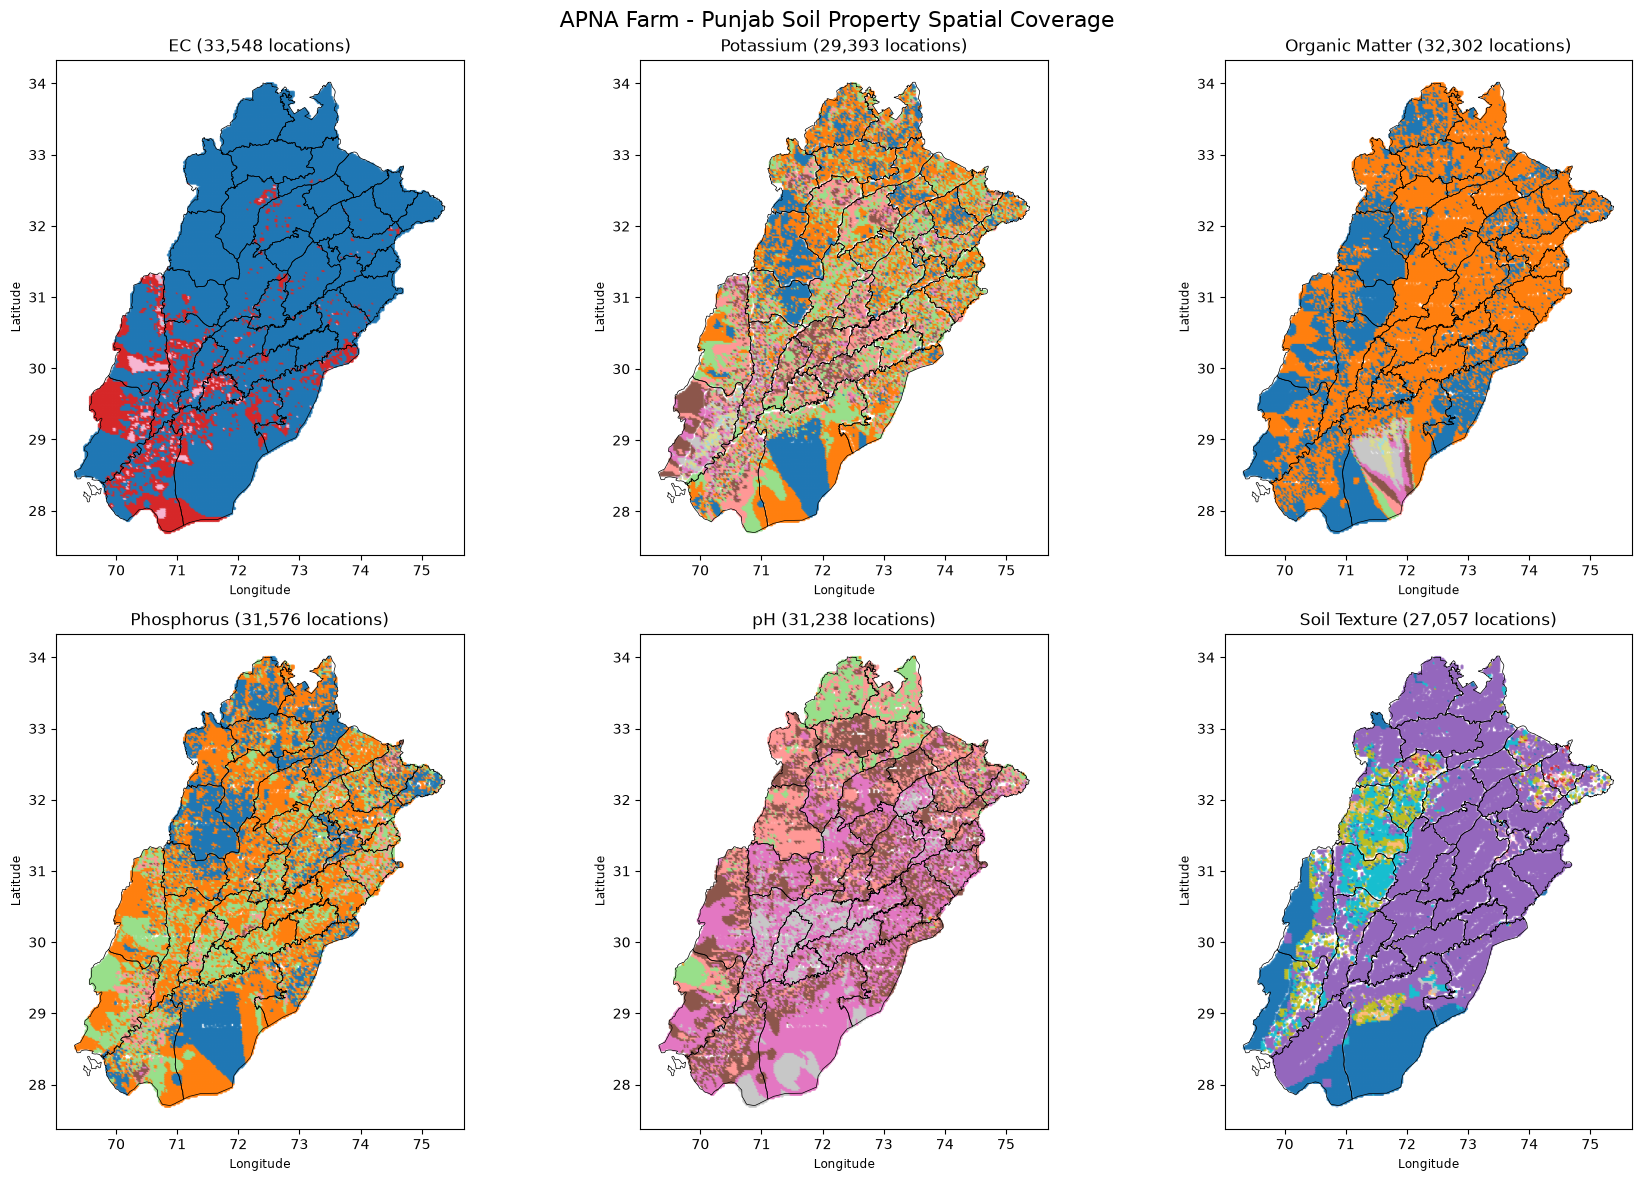

Saved: D:\SoilSenseAI\outputs\eda\08_apna_farm_spatial_coverage.png


In [12]:

# Purpose: Visualize geographic coverage of all six APNA Farm soil properties.

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

# Load unified dataset and Punjab district boundaries.
apna_dir = Path(r"D:\SoilSenseAI\data\processed\ApnaFarmData")
project_dir = Path(r"D:\SoilSenseAI")

df = pd.read_csv(
    apna_dir / "punjab_apna_farm_soil_dataset.csv"
)

punjab = gpd.read_file(
    project_dir / "data" / "processed" / "punjab_districts.geojson"
)

properties = {
    "EC": "ec",
    "Potassium": "k",
    "Organic Matter": "om",
    "Phosphorus": "p",
    "pH": "ph",
    "Soil Texture": "texture"
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, (name, prefix) in zip(axes.flat, properties.items()):

    # Plot district boundaries.
    punjab.boundary.plot(
        ax=ax,
        color="black",
        linewidth=0.5
    )

    # Keep locations where this property was extracted.
    valid = df[df[f"{prefix}_class_id"].notna()]

    # Plot extracted geographic locations.
    ax.scatter(
        valid["longitude"],
        valid["latitude"],
        c=valid[f"{prefix}_class_id"],
        cmap="tab20",
        s=2,
        alpha=0.7
    )

    ax.set_title(f"{name} ({len(valid):,} locations)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.suptitle(
    "APNA Farm - Punjab Soil Property Spatial Coverage",
    fontsize=16
)

plt.tight_layout()

output_path = project_dir / "outputs" / "eda" / "08_apna_farm_spatial_coverage.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


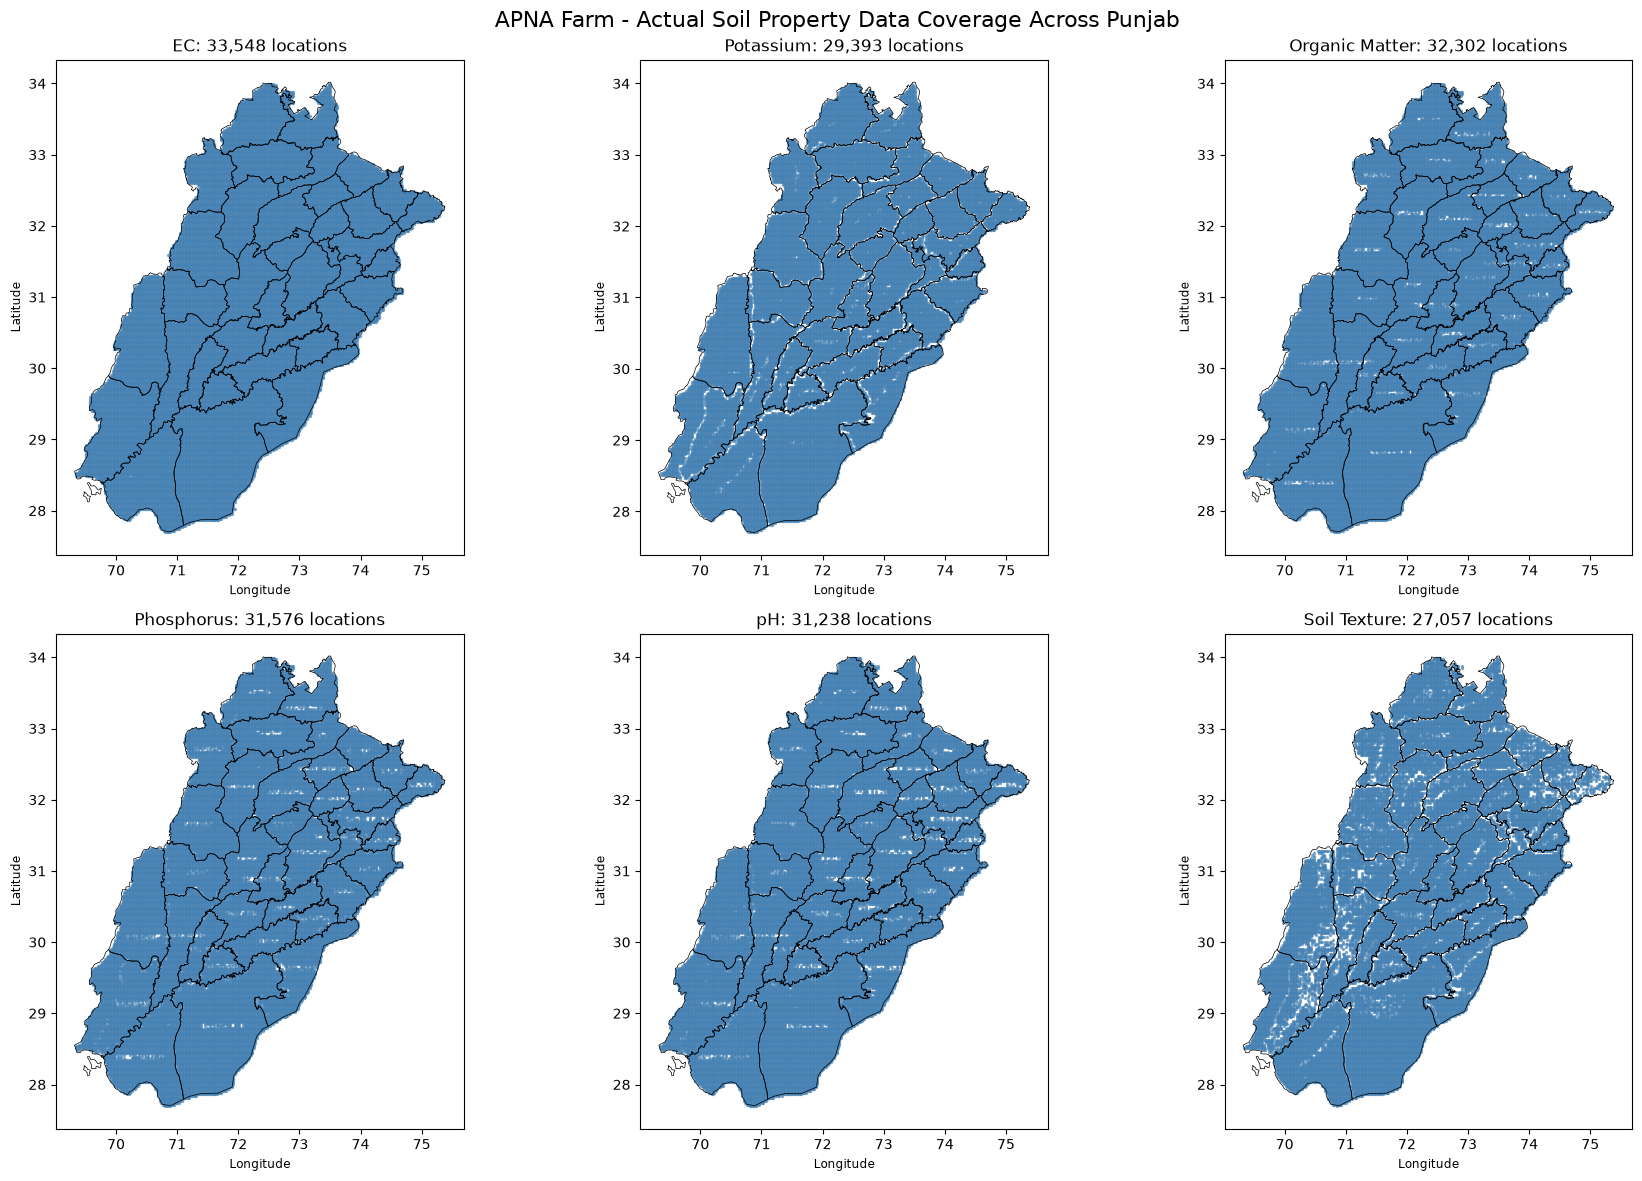

Saved: D:\SoilSenseAI\outputs\eda\09_apna_farm_actual_coverage.png


In [13]:

# Purpose: Visualize actual APNA Farm data coverage, independent of soil classes.

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path(r"D:\SoilSenseAI")
apna_dir = project_dir / "data" / "processed" / "ApnaFarmData"

df = pd.read_csv(
    apna_dir / "punjab_apna_farm_soil_dataset.csv"
)

punjab = gpd.read_file(
    project_dir / "data" / "processed" / "punjab_districts.geojson"
)

properties = {
    "EC": "ec",
    "Potassium": "k",
    "Organic Matter": "om",
    "Phosphorus": "p",
    "pH": "ph",
    "Soil Texture": "texture"
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, (name, prefix) in zip(axes.flat, properties.items()):

    # Draw Punjab district boundaries.
    punjab.boundary.plot(
        ax=ax,
        color="black",
        linewidth=0.5
    )

    # Select locations with available property data.
    valid = df[df[f"{prefix}_class_id"].notna()]

    # Plot every valid location using one color.
    ax.scatter(
        valid["longitude"],
        valid["latitude"],
        color="steelblue",
        s=2,
        alpha=0.6
    )

    ax.set_title(f"{name}: {len(valid):,} locations")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.suptitle(
    "APNA Farm - Actual Soil Property Data Coverage Across Punjab",
    fontsize=16
)

plt.tight_layout()

output_path = project_dir / "outputs" / "eda" / "09_apna_farm_actual_coverage.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


In [3]:

# Validate the extracted phosphorus CSV structure and basic data quality.

import pandas as pd
from pathlib import Path

# Change this path to your actual CSV location.
csv_path = Path(r"D:\SoilSenseAI\data\processed\ApnaFarmData\punjab_soil_p_cells.csv")

df = pd.read_csv(csv_path)

print("DATASET SHAPE:", df.shape)
print("\nCOLUMNS:")
print(df.columns.tolist())

print("\nFIRST 5 ROWS:")
display(df.head())

print("\nMISSING VALUES:")
print(df.isna().sum())

print("\nCOORDINATE BOUNDS:")
print("Longitude:", df["longitude"].min(), "to", df["longitude"].max())
print("Latitude:", df["latitude"].min(), "to", df["latitude"].max())

print("\nDUPLICATE COORDINATES:")
print(df.duplicated(["longitude", "latitude"]).sum())

print("\nCLASS DISTRIBUTION:")
print(df["class_id"].value_counts().sort_index())

print("\nCLASS PERCENTAGES:")
print((df["class_id"].value_counts(normalize=True).sort_index() * 100).round(2))


DATASET SHAPE: (31576, 8)

COLUMNS:
['longitude', 'latitude', 'property_name', 'class_id', 'value_min', 'value_max', 'value_midpoint', 'extraction_method']

FIRST 5 ROWS:


,longitude,latitude,property_name,class_id,value_min,value_max,value_midpoint,extraction_method
0,72.44422,33.99695,Soil P,2,4.5100,7.83,6.1700,legend_nearest_CIELAB_dE<=12|cell_window_5x5_f...
1,72.46828,33.99695,Soil P,2,4.5100,7.83,6.1700,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...
2,72.49234,33.99695,Soil P,2,4.5100,7.83,6.1700,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...
3,72.51640,33.99695,Soil P,2,4.5100,7.83,6.1700,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...
4,72.54046,33.99695,Soil P,1,0.0766,4.50,2.2883,legend_nearest_CIELAB_dE<=12|cell_centre_3x3_p...



MISSING VALUES:
longitude            0
latitude             0
property_name        0
class_id             0
value_min            0
value_max            0
value_midpoint       0
extraction_method    0
dtype: int64

COORDINATE BOUNDS:
Longitude: 69.34072 to 75.3312
Latitude: 27.69366 to 33.99695

DUPLICATE COORDINATES:
0

CLASS DISTRIBUTION:
class_id
1     7267
2    15426
3     7101
4     1477
5      267
6       22
7        7
8        5
9        4
Name: count, dtype: int64

CLASS PERCENTAGES:
class_id
1    23.01
2    48.85
3    22.49
4     4.68
5     0.85
6     0.07
7     0.02
8     0.02
9     0.01
Name: proportion, dtype: float64


In [4]:

# Check whether extracted phosphorus coordinates fall inside Punjab districts.

import geopandas as gpd
import pandas as pd
from pathlib import Path

# Load extracted phosphorus data and Punjab district boundaries.
csv_path = Path(r"D:\SoilSenseAI\data\processed\ApnaFarmData\punjab_soil_p_cells.csv")
boundary_path = Path(r"D:\SoilSenseAI\data\processed\punjab_districts.geojson")

df = pd.read_csv(csv_path)
punjab = gpd.read_file(boundary_path)

# Convert coordinates into geographic points.
points = gpd.GeoDataFrame(
    df.copy(),
    geometry=gpd.points_from_xy(df.longitude, df.latitude),
    crs="EPSG:4326"
)

# Check which points fall inside Punjab.
joined = gpd.sjoin(
    points,
    punjab[["adm2_name", "geometry"]],
    how="left",
    predicate="within"
)

print("TOTAL CELLS:", len(joined))
print("INSIDE PUNJAB:", joined["adm2_name"].notna().sum())
print("OUTSIDE PUNJAB:", joined["adm2_name"].isna().sum())

print("\nDISTRICT COVERAGE:")
print(joined["adm2_name"].value_counts().sort_index())

print("\nCLASS DISTRIBUTION INSIDE PUNJAB:")
print(joined.loc[joined["adm2_name"].notna(), "class_id"].value_counts().sort_index())


TOTAL CELLS: 31576
INSIDE PUNJAB: 31286
OUTSIDE PUNJAB: 290

DISTRICT COVERAGE:
adm2_name
Attock             1113
Bahawalnagar       1303
Bahawalpur         3753
Bhakkar            1338
Chakwal            1032
Chiniot             397
Dera Ghazi Khan    1802
Faisalabad          896
Gujranwala          552
Gujrat              478
Hafizabad           329
Jhang               964
Jhelum              548
Kasur               616
Khanewal            649
Khushab            1037
Lahore              246
Layyah              999
Lodhran             382
Mandi Bahauddin     390
Mianwali            912
Multan              550
Muzaffargarh       1189
Nankana Sahib       311
Narowal             334
Okara               675
Pakpattan           421
Rahim Yar Khan     1905
Rajanpur           1884
Rawalpindi          782
Sahiwal             476
Sargodha            890
Sheikhupura         526
Sialkot             467
Toba Tek Singh      466
Vehari              674
Name: count, dtype: int64

CLASS DISTRIBUTION 

OUTSIDE CELLS: 290

OUTSIDE COORDINATE RANGES:
Longitude: 69.50913 to 75.06656
Latitude: 27.69366 to 33.99695

OUTSIDE CLASS DISTRIBUTION:
class_id
1     58
2    166
3     58
4      8
Name: count, dtype: int64


,longitude,latitude,class_id,value_min,value_max
1,72.46828,33.99695,2,4.5100,7.83
4,72.54046,33.99695,1,0.0766,4.50
5,72.56451,33.99695,1,0.0766,4.50
6,72.58857,33.99695,1,0.0766,4.50
14,72.56451,33.97289,1,0.0766,4.50
15,72.58857,33.97289,1,0.0766,4.50
16,72.61263,33.97289,1,0.0766,4.50
20,72.32393,33.94883,3,7.8400,12.30
21,72.34799,33.94883,3,7.8400,12.30
74,72.63669,33.90072,1,0.0766,4.50


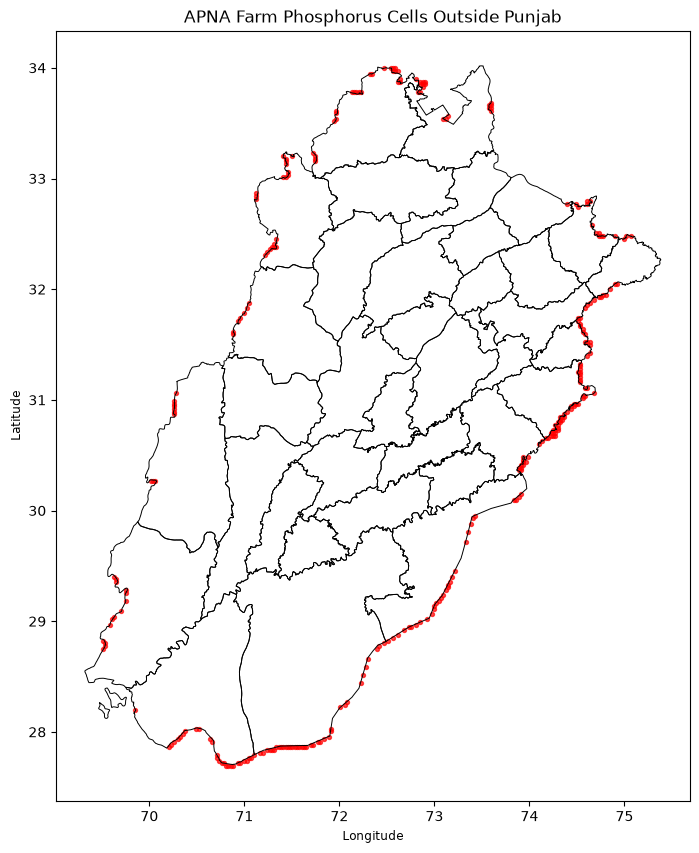

In [5]:

# Investigate phosphorus cells falling outside Punjab boundaries.

outside = joined[joined["adm2_name"].isna()].copy()

print("OUTSIDE CELLS:", len(outside))

print("\nOUTSIDE COORDINATE RANGES:")
print("Longitude:", outside.longitude.min(), "to", outside.longitude.max())
print("Latitude:", outside.latitude.min(), "to", outside.latitude.max())

print("\nOUTSIDE CLASS DISTRIBUTION:")
print(outside["class_id"].value_counts().sort_index())

# Display the first 20 outside coordinates.
display(
    outside[
        ["longitude", "latitude", "class_id", "value_min", "value_max"]
    ].head(20)
)

# Plot outside cells against Punjab boundary.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

punjab.boundary.plot(ax=ax, color="black", linewidth=0.7)

outside.plot(
    ax=ax,
    color="red",
    markersize=8,
    alpha=0.7
)

ax.set_title("APNA Farm Phosphorus Cells Outside Punjab")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()


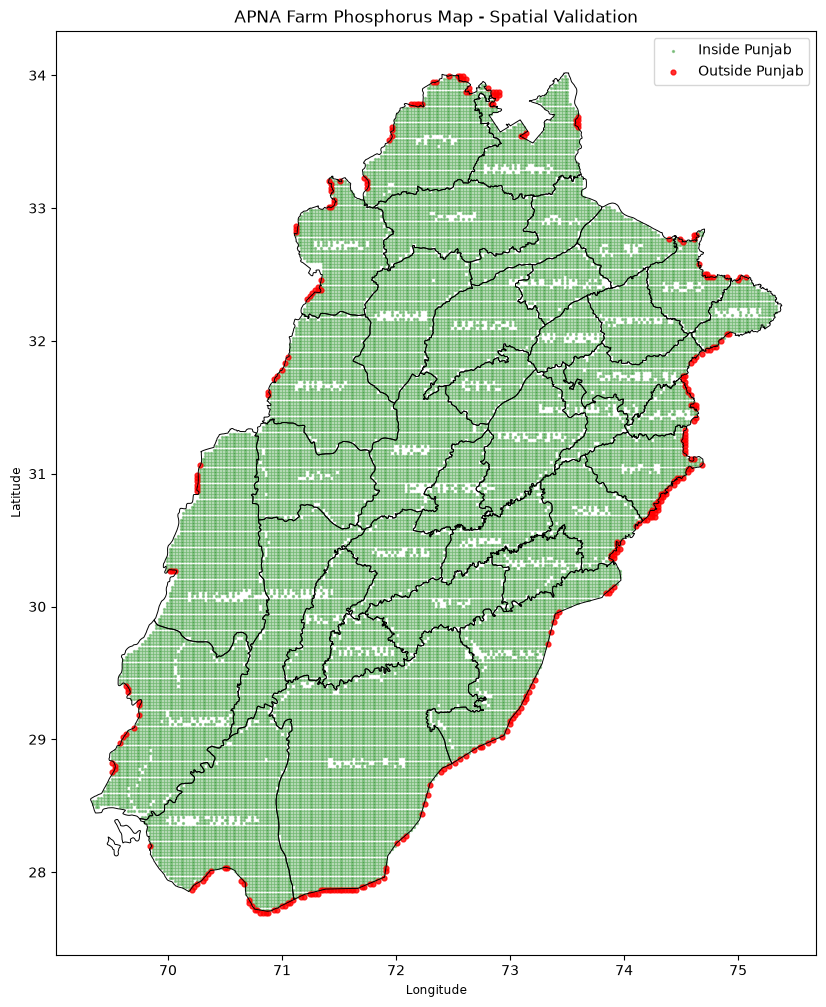

In [6]:

# Visualize all phosphorus cells against Punjab district boundaries.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

# Plot Punjab districts.
punjab.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.7
)

# Plot valid points.
inside = joined[joined["adm2_name"].notna()]
inside.plot(
    ax=ax,
    color="green",
    markersize=2,
    alpha=0.35,
    label="Inside Punjab"
)

# Plot outside points.
outside = joined[joined["adm2_name"].isna()]
outside.plot(
    ax=ax,
    color="red",
    markersize=12,
    alpha=0.8,
    label="Outside Punjab"
)

ax.set_title("APNA Farm Phosphorus Map - Spatial Validation")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()

plt.show()


In [ ]:

# Measure the distance of outside points from the nearest Punjab boundary.

outside_metric = outside_check.to_crs("EPSG:32643")
punjab_metric = punjab.to_crs("EPSG:32643")

punjab_union = punjab_metric.geometry.union_all()

outside_metric["distance_from_punjab_km"] = (
    outside_metric.geometry.distance(punjab_union) / 1000
)

print("Distance from Punjab boundary (km):")
display(
    outside_metric["distance_from_punjab_km"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

print("Farthest outside point (km):",
      outside_metric["distance_from_punjab_km"].max())


Distance from Punjab boundary (km):


,distance_from_punjab_km
count,290.000000
mean,0.946056
std,0.834059
min,0.009307
25%,0.330488
50%,0.767771
75%,1.387653
90%,1.818862
95%,2.276576
99%,4.028179


Farthest outside point (km): 6.256703838307761



# 08 - APNA Farm Soil Map Digitization and Data Preparation

## 1. Project Overview

This notebook focuses on extracting, validating, and integrating soil-property information from APNA Farm's digitized soil maps covering Punjab, Pakistan.

APNA Farm provides spatial soil information for several important agricultural properties. However, the underlying numerical datasets were not made available to us. Therefore, the maps were digitized to create structured, georeferenced datasets for the SoilSenseAI project.

The objective is to convert these map-based representations into usable geospatial data while preserving their original classification intervals, spatial coordinates, and extraction provenance.

### Soil Properties

The following six soil properties were digitized:

1. Soil pH
2. Phosphorus (P)
3. Potassium (K)
4. Organic Matter (OM)
5. Electrical Conductivity (EC)
6. Soil Texture

## 2. Data Sources and Storage

All digitized APNA Farm CSV files are stored in:

`data/processed/ApnaFarmData/`

### Source Files

| Property | Filename |
|---|---|
| EC | punjab_soil_ec_cells.csv |
| Potassium | punjab_soil_k_cells.csv |
| Organic Matter | punjab_soil_om_cells.csv |
| Phosphorus | punjab_soil_p_cells.csv |
| Phosphorus QA | punjab_soil_p_cells_qa.csv |
| pH | punjab_soil_ph_cells.csv |
| Soil Texture | punjab_soil_texture_cells.csv |

The phosphorus QA file contains additional extraction-quality information and is maintained separately from the primary property datasets.

## 3. Digitization Methodology

The APNA Farm maps were digitized using map-image analysis and legend-based colour classification.

The extraction workflow included:

- Identifying the Punjab map area.
- Identifying legend colours and corresponding soil-property classes.
- Georeferencing map pixels using geographic graticule coordinates.
- Converting extracted map cells into longitude and latitude coordinates.
- Assigning each cell its corresponding class and legend interval.
- Preserving extraction-method information for traceability.

Colour classification used nearest-colour matching in CIELAB colour space.

The resulting coordinates represent approximate cell-centre locations, not original laboratory sampling points.

### Important Interpretation

The extracted values represent digitized map classes and their legend intervals. They must not be interpreted as exact laboratory measurements.

The spatial grid also does not represent the original resolution of APNA Farm's underlying sampling or interpolation process.

## 4. Dataset Inventory and Schema Validation

All six primary property datasets and the phosphorus QA file were successfully located.

The numeric property datasets contain the following common fields:

- longitude
- latitude
- property_name
- class_id
- value_min
- value_max
- value_midpoint
- extraction_method

The soil texture dataset additionally contains `class_label`, because texture is categorical rather than a continuous numerical property.

The phosphorus QA dataset contains pixel coordinates, extraction status, colour-distance information, and cell-purity measurements.

## 5. Individual Dataset Validation

The six primary datasets were inspected for:

- Record counts.
- Missing values.
- Duplicate geographic coordinates.
- Number of distinct classes.
- Geographic coordinate ranges.

### Validation Results

| Property | Records | Missing Values | Duplicate Coordinates | Classes |
|---|---:|---:|---:|---:|
| EC | 33,548 | 0 | 0 | 4 |
| Potassium | 29,393 | 0 | 0 | 9 |
| Organic Matter | 32,302 | 0 | 0 | 9 |
| Phosphorus | 31,576 | 0 | 0 | 9 |
| pH | 31,238 | 0 | 0 | 9 |
| Soil Texture | 27,057 | 81,171 | 0 | 10 |

The 81,171 missing values in the texture dataset occur in its three numerical interval fields (`value_min`, `value_max`, and `value_midpoint`).

These fields are not applicable to categorical texture classes. The `class_label` field is retained as the meaningful texture classification.

No duplicate coordinates were found in any of the six primary datasets.

## 6. Spatial Coverage and Coordinate Overlap

The geographic coordinates of all six datasets were compared to determine their spatial overlap.

### Results

- Unique locations across all datasets: 33,643
- Locations shared by all six properties: 25,345
- Locations not shared by all six: 8,298

### Coverage of Common Locations

| Property | Total Locations | Shared Locations (%) |
|---|---:|---:|
| EC | 33,548 | 75.55% |
| Potassium | 29,393 | 86.23% |
| Organic Matter | 32,302 | 78.46% |
| Phosphorus | 31,576 | 80.27% |
| pH | 31,238 | 81.14% |
| Soil Texture | 27,057 | 93.67% |

These results show that the six properties do not have identical spatial coverage.

A complete six-property dataset is available at 25,345 shared locations. However, retaining locations with incomplete property information provides broader geographic coverage.

## 7. Unified APNA Farm Soil Dataset

An outer merge was performed using rounded longitude and latitude coordinates as matching keys.

The outer merge preserves locations even when one or more soil properties are unavailable.

### Unified Dataset Results

- Total geographic locations: 33,643
- Total columns: 39
- Integrated soil properties: 6
- Locations lost during merging: 0

### Output File

`punjab_apna_farm_soil_dataset.csv`

The unified dataset contains separate property-specific fields, including:

- Class identifiers.
- Minimum and maximum legend values.
- Class midpoints.
- Extraction methods.
- Soil texture labels.

Missing values are retained as NaN rather than being artificially filled.

The original source CSV files remain unchanged.

## 8. Spatial Visualization

A six-panel spatial visualization was generated to examine the distribution of extracted soil-property classes across Punjab.

The visualization includes:

1. Electrical Conductivity
2. Potassium
3. Organic Matter
4. Phosphorus
5. Soil pH
6. Soil Texture

District boundaries were overlaid using the Punjab administrative boundary dataset.

### Output

`outputs/eda/08_apna_farm_spatial_coverage.png`

The maps illustrate differences in the spatial distribution of extracted classes and the geographic coverage of each property.

## 9. Data Limitations and Considerations

The following limitations must be considered in subsequent modelling and analysis:

1. The datasets were digitized from map images rather than obtained as original sample-level laboratory records.
2. Extracted class midpoints are representative values of legend intervals, not exact soil measurements.
3. The APNA Farm map grid has an approximate cell spacing of 0.024 degrees, corresponding to roughly 2.3 × 2.7 km in the region, although spacing and coverage may vary.
4. Some classes have similar legend colours, which can introduce classification uncertainty.
5. The digitized coordinates represent map-cell centres and should not be interpreted as independent soil sampling locations.
6. Spatial coverage differs among the six properties.
7. The source maps' complete analytical methods and measurement units have not yet been independently verified.
8. The phosphorus QA dataset should be retained for future extraction-quality assessment.

These datasets should therefore be treated as digitized spatial map estimates, not independent ground-truth observations.

## 10. Conclusion

This notebook successfully converted six APNA Farm soil-property maps into structured, georeferenced CSV datasets.

The individual datasets were inspected, their spatial overlap was evaluated, and a unified dataset containing 33,643 unique geographic locations was created.

The resulting dataset provides additional soil-property information for the Punjab-wide SoilSenseAI project, particularly for properties such as phosphorus, potassium, and electrical conductivity that are not directly available in the current SoilGrids feature set.

The next stage will compare compatible properties from APNA Farm and SoilGrids while accounting for differences in spatial resolution, measurement definitions, and data provenance.

## 11. Next Notebook

**Notebook 09 - APNA Farm and SoilGrids Spatial Comparison**

The next stage will focus on:

- Comparing geographic coverage.
- Identifying comparable soil properties.
- Matching datasets at compatible spatial scales.
- Comparing pH, organic matter-related indicators, and soil texture.
- Evaluating differences between digitized map estimates and SoilGrids predictions.
